# VaR con simulación Monte Carlo

<div class="aperture-pasos">

## Monte Carlo aplicado al VaR

1. **Generación de números aleatorios uniformes**<br>
2. **Conversión a variables normales**<br>
3. **Construcción de la matriz de covarianza del mercado**<br>
4. **Factorización de la matriz**<br>
5. **Creación de shocks correlacionados**<br>
6. **Revalorización** *(Repricing)*<br>
7. **Estimación del VaR**<br>
</div>

### Datos: acción de Amazon (AMZN)

Precios de cierre ajustados descargados de Yahoo Finance con `yfinance`. El portafolio es una posición de USD 10,000 en AMZN y se estima el VaR a 1 día con 99% de confianza. El código está escrito para una lista de activos: para analizar un portafolio basta con agregar tickers a `TICKERS` y sus pesos a `PESOS`.

In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
from scipy import stats

# Parámetros del análisis
TICKERS = ["AMZN"]
PESOS = np.array([1.0])  # fracción del portafolio en cada activo
VALOR_PORTAFOLIO = 10_000  # USD
INICIO, FIN = "2023-11-01", "2026-11-01"
CONFIANZA = 0.99
HORIZONTE = 1  # días
N_SIM = 100_000
SEMILLA = 42

precios = yf.download(TICKERS, start=INICIO, end=FIN, auto_adjust=True, progress=False)[
    "Close"
][TICKERS]
rendimientos = np.log(precios).diff().dropna()

print(
    f"Observaciones: {len(precios)} días, de {precios.index[0]:%Y-%m-%d} a {precios.index[-1]:%Y-%m-%d}"
)
precios.tail()

Observaciones: 752 días, de 2023-11-01 a 2026-10-30


Ticker,AMZN
Date,
2026-10-26,249.089996
2026-10-27,253.100006
2026-10-28,254.600006
2026-10-29,243.789993
2026-10-30,240.350006


In [2]:
# Gráficas con la estética de la charla: el código está en graficas.py
import graficas

graficas.aplicar_estilo()

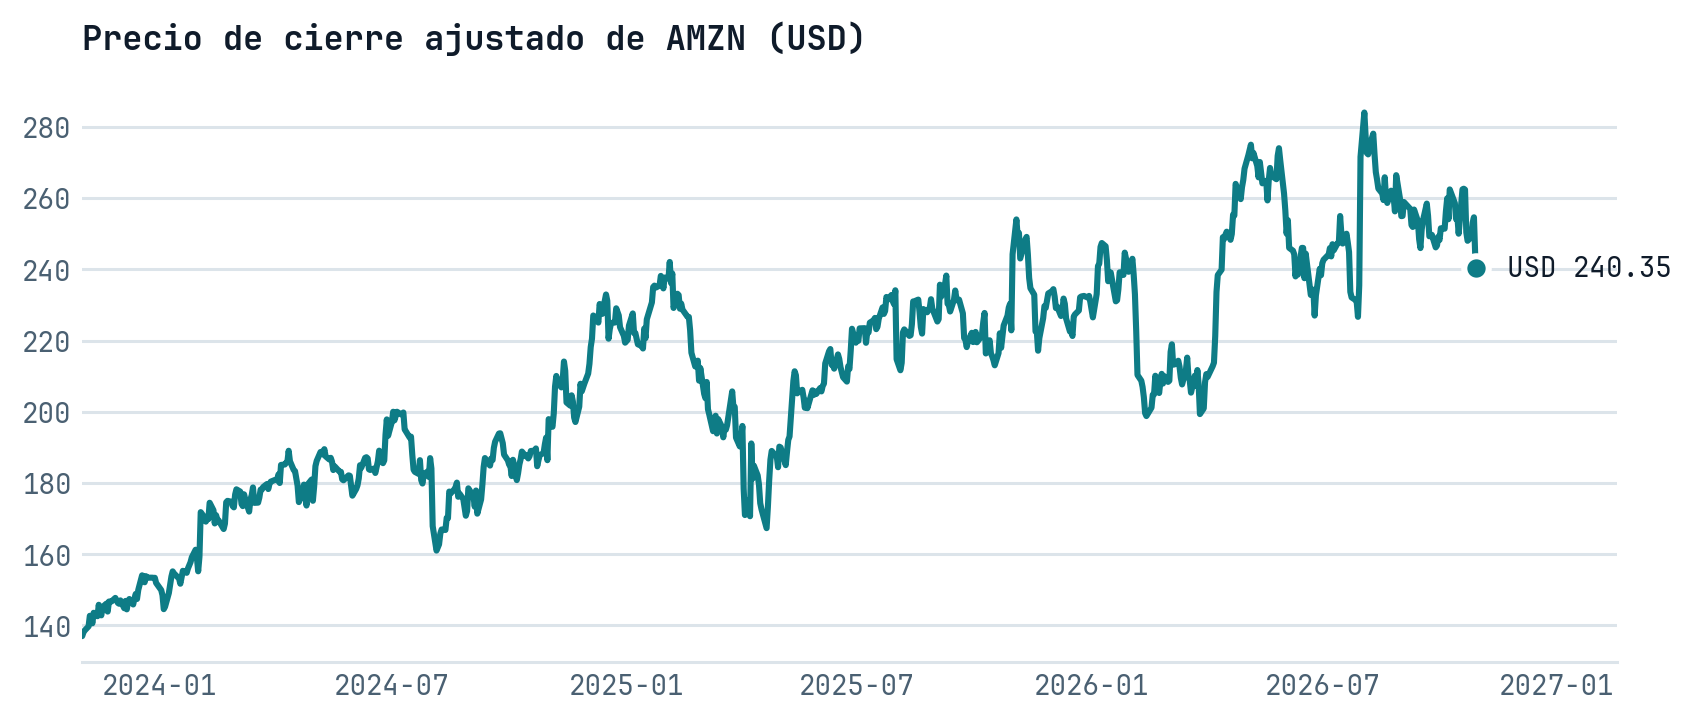

In [3]:
graficas.precio(precios[TICKERS[0]])

In [4]:
# Resumen de los rendimientos logarítmicos diarios
resumen = pd.DataFrame(
    {
        "media diaria": rendimientos.mean(),
        "volatilidad diaria": rendimientos.std(),
        "volatilidad anual": rendimientos.std() * np.sqrt(252),
        "asimetría": rendimientos.apply(stats.skew),
        "curtosis (exceso)": rendimientos.apply(stats.kurtosis),
    }
)
resumen.round(4)

,media diaria,volatilidad diaria,volatilidad anual,asimetría,curtosis (exceso)
Ticker,,,,,
AMZN,0.0007,0.0199,0.3166,0.5005,6.5964


## Generación de números aleatorios uniformes

Secuencias pseudoaleatorias entre 0 y 1 generadas por un algoritmo.

In [5]:
n_activos = len(TICKERS)
rng = np.random.default_rng(SEMILLA)

# Matriz N_SIM x n_activos de uniformes U(0, 1)
U = rng.uniform(size=(N_SIM, n_activos))

# Chequeo: una U(0, 1) tiene media 1/2 y varianza 1/12
pd.DataFrame(
    {
        "simulado": [U.mean(), U.var(), U.min(), U.max()],
        "teórico": [1 / 2, 1 / 12, 0, 1],
    },
    index=["media", "varianza", "mínimo", "máximo"],
).round(4)

,simulado,teórico
media,0.5006,0.5000
varianza,0.0832,0.0833
mínimo,0.0000,0.0000
máximo,1.0000,1.0000


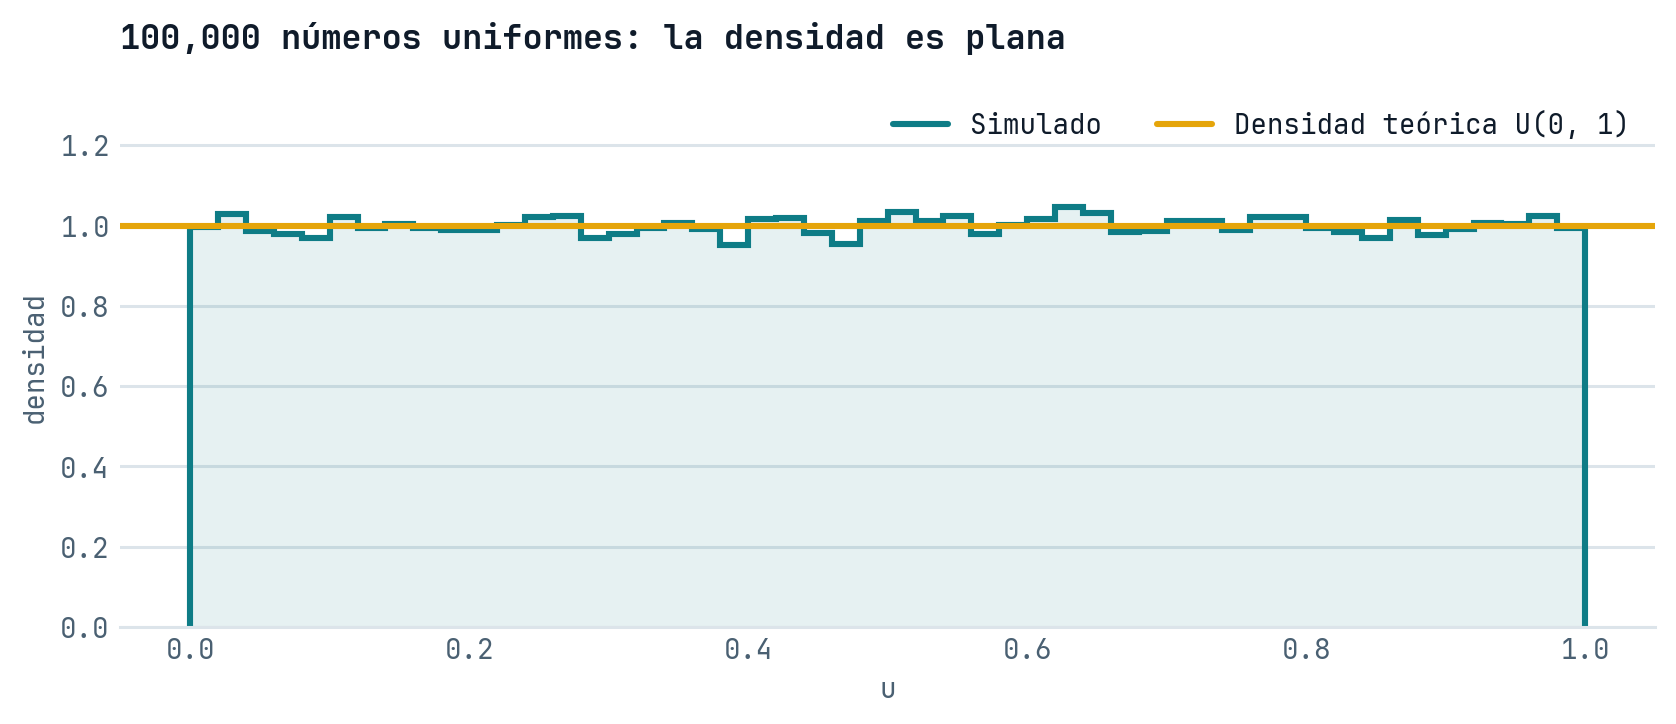

In [6]:
graficas.uniformes(U[:, 0])

## Conversión a variables normales

Transformar los valores uniformes a una normal estándar.

In [7]:
# Transformada inversa: si U ~ U(0, 1), entonces Φ⁻¹(U) ~ N(0, 1)
Z = stats.norm.ppf(U)

# Prueba de Kolmogorov-Smirnov contra la normal estándar
ks = stats.kstest(Z[:, 0], "norm")
pd.DataFrame(
    {
        "simulado": [
            Z.mean(),
            Z.std(),
            stats.skew(Z[:, 0]),
            stats.kurtosis(Z[:, 0]),
            ks.pvalue,
        ],
        "teórico": [0, 1, 0, 0, None],
    },
    index=["media", "desv. estándar", "asimetría", "curtosis (exceso)", "p-valor KS"],
).round(4)

,simulado,teórico
media,0.0015,0.0
desv. estándar,1.0007,1.0
asimetría,-0.0086,0.0
curtosis (exceso),0.0165,0.0
p-valor KS,0.3313,NaN


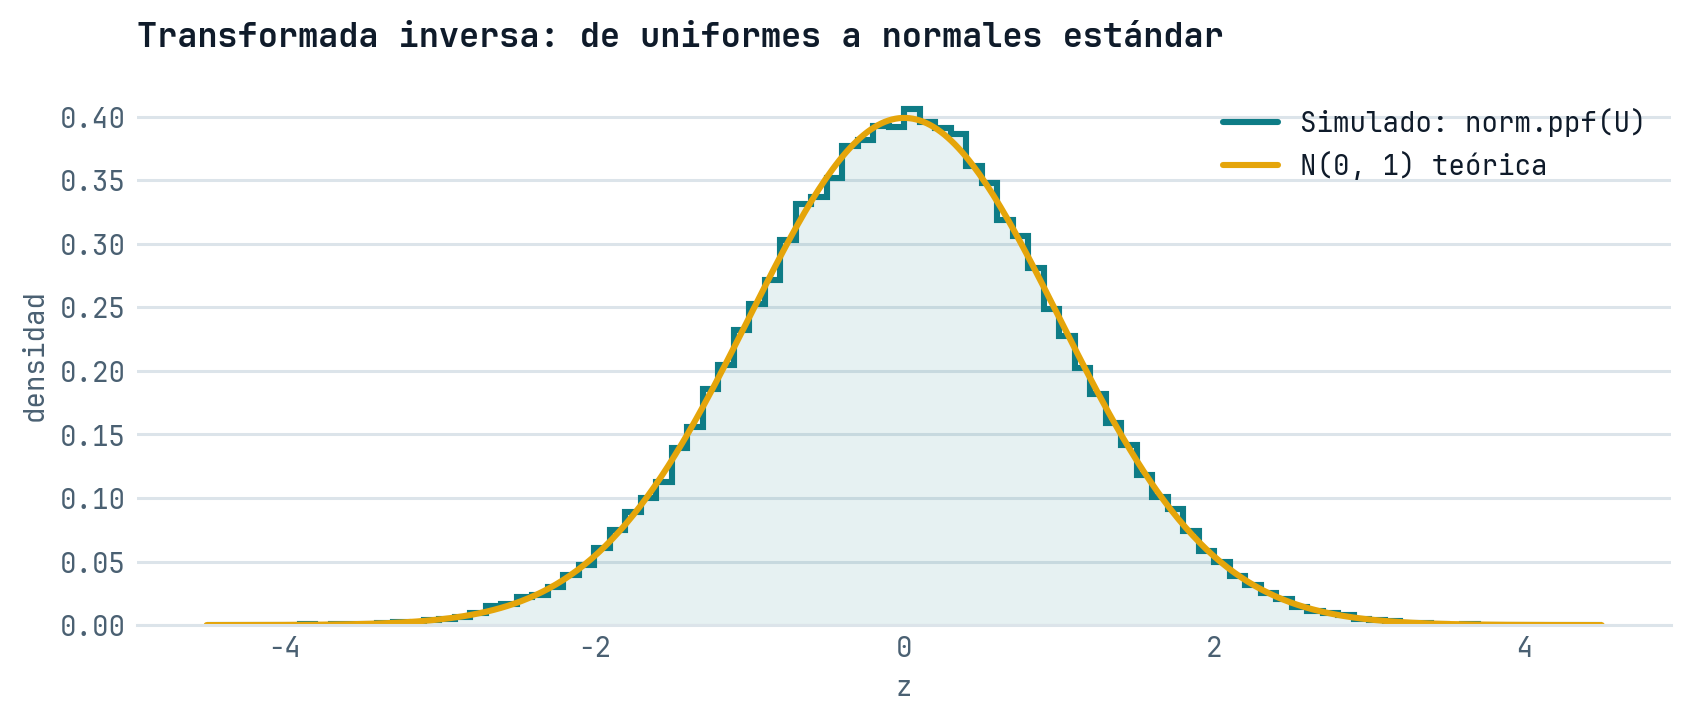

In [8]:
graficas.normales(Z[:, 0])

## Construcción de la matriz de covarianza del mercado

Volatilidades y correlaciones entre los activos.

In [9]:
mu = rendimientos.mean().values  # vector de medias diarias
cov = rendimientos.cov().values  # matriz de covarianza diaria

# Con un solo activo la matriz es 1x1 y su único elemento es la varianza
print("Matriz de covarianza diaria:")
display(pd.DataFrame(cov, index=TICKERS, columns=TICKERS))
print("Matriz de correlación:")
rendimientos.corr()

Matriz de covarianza diaria:


,AMZN
AMZN,0.000398


Matriz de correlación:


Ticker,AMZN
Ticker,
AMZN,1.0


## Factorización de la matriz

Obtener su "raíz cuadrada" con Cholesky o autovalores.

In [10]:
# Cholesky: cov = L @ L.T, con L triangular inferior
L = np.linalg.cholesky(cov)

print("Factor de Cholesky L:")
display(pd.DataFrame(L, index=TICKERS, columns=TICKERS))
print("¿L @ L.T reproduce la covarianza?", np.allclose(L @ L.T, cov))
print(
    f"Con un activo, L es la volatilidad diaria: {L[0, 0]:.4%} vs {rendimientos.std().iloc[0]:.4%}"
)

Factor de Cholesky L:


,AMZN
AMZN,0.019945


¿L @ L.T reproduce la covarianza? True
Con un activo, L es la volatilidad diaria: 1.9945% vs 1.9945%


## Creación de shocks correlacionados

Combinar normales y matriz factorizada en variaciones correlacionadas.

In [11]:
# Rendimientos simulados al horizonte: media + Z correlacionado por L
shocks = mu * HORIZONTE + (Z @ L.T) * np.sqrt(HORIZONTE)

pd.DataFrame(
    {
        "media simulada": shocks.mean(axis=0),
        "media histórica": mu * HORIZONTE,
        "volatilidad simulada": shocks.std(axis=0),
        "volatilidad histórica": np.sqrt(np.diag(cov) * HORIZONTE),
    },
    index=TICKERS,
).round(5)

,media simulada,media histórica,volatilidad simulada,volatilidad histórica
AMZN,0.00078,0.00075,0.01996,0.01995


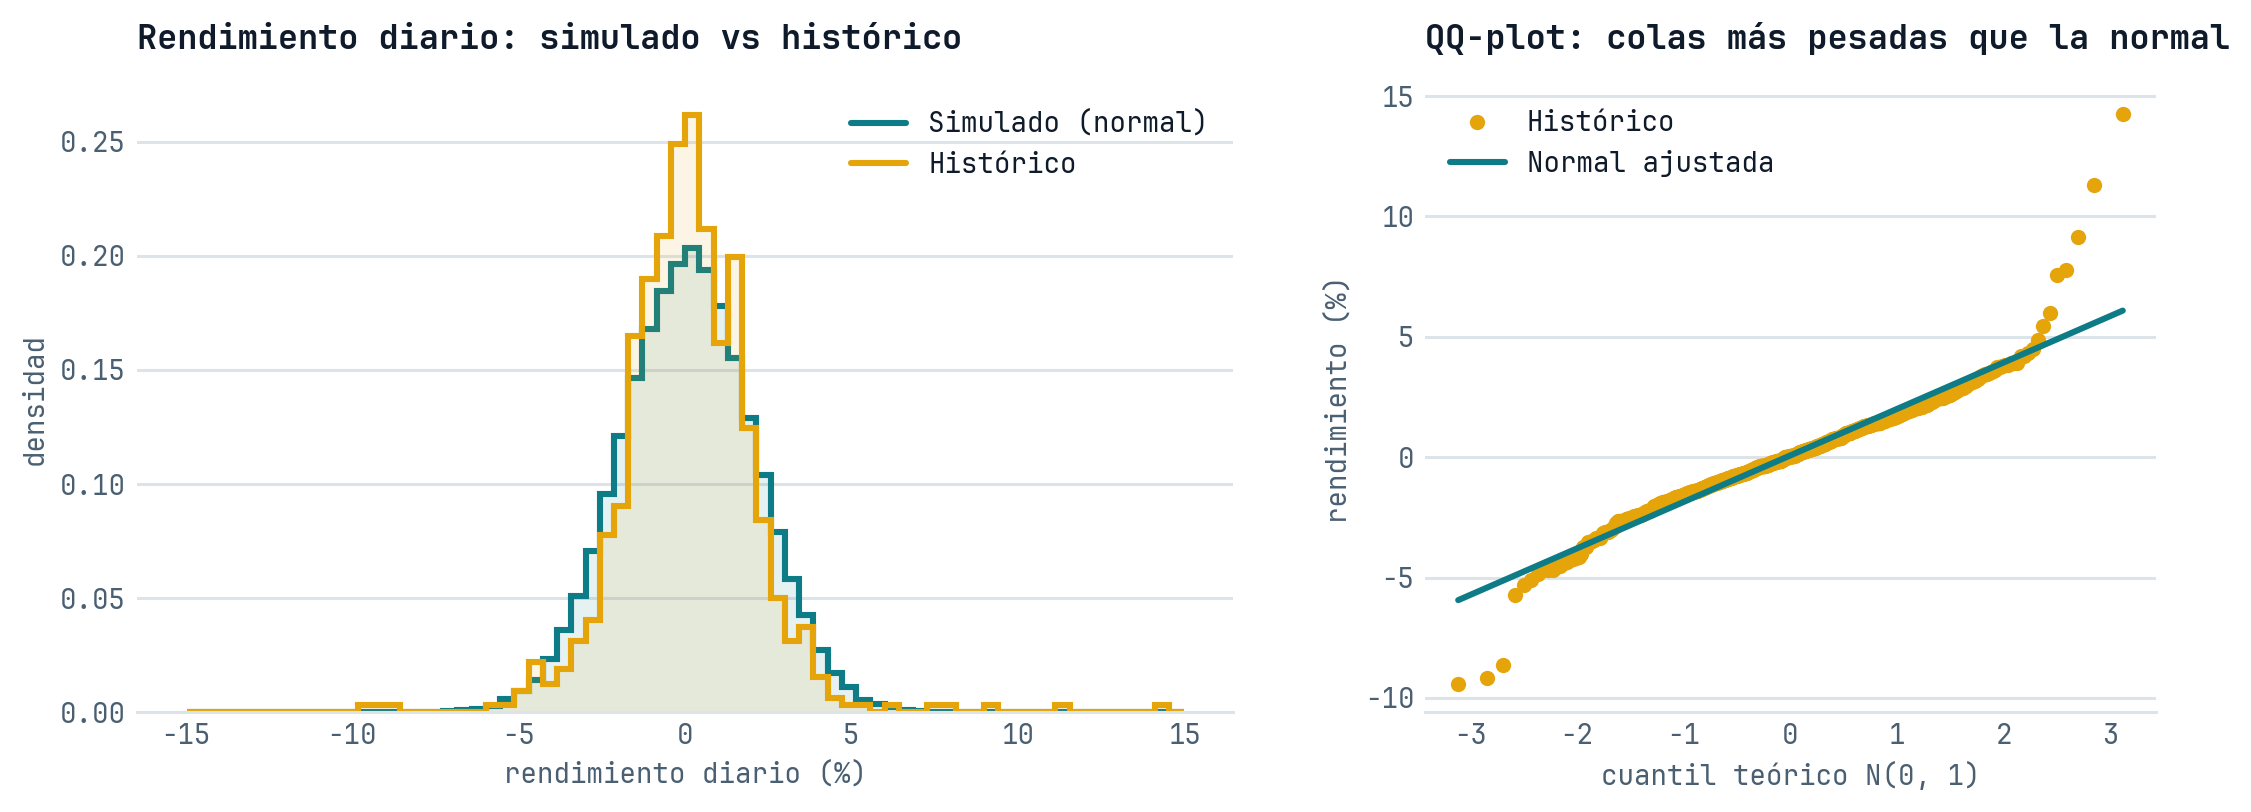

In [12]:
graficas.shocks_vs_historico(shocks[:, 0], rendimientos[TICKERS[0]])

## Revalorización (Repricing)

Recalcular el P&L del portafolio en cada escenario simulado.

In [13]:
S0 = precios.iloc[-1].values  # último precio observado
acciones = VALOR_PORTAFOLIO * PESOS / S0  # número de acciones de cada activo

# Revalorización completa: precio en cada escenario y P&L del portafolio
S_T = S0 * np.exp(shocks)
pnl = (S_T - S0) @ acciones

print(f"Precio inicial de AMZN: USD {S0[0]:,.2f}  |  acciones: {acciones[0]:,.2f}")
pd.Series(pnl, name="P&L (USD)").describe(
    percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
).round(2).to_frame()

Precio inicial de AMZN: USD 240.35  |  acciones: 41.61


,P&L (USD)
count,100000.00
mean,9.78
std,199.78
min,-797.24
1%,-450.26
5%,-316.45
50%,8.72
95%,342.05
99%,483.97
max,918.47


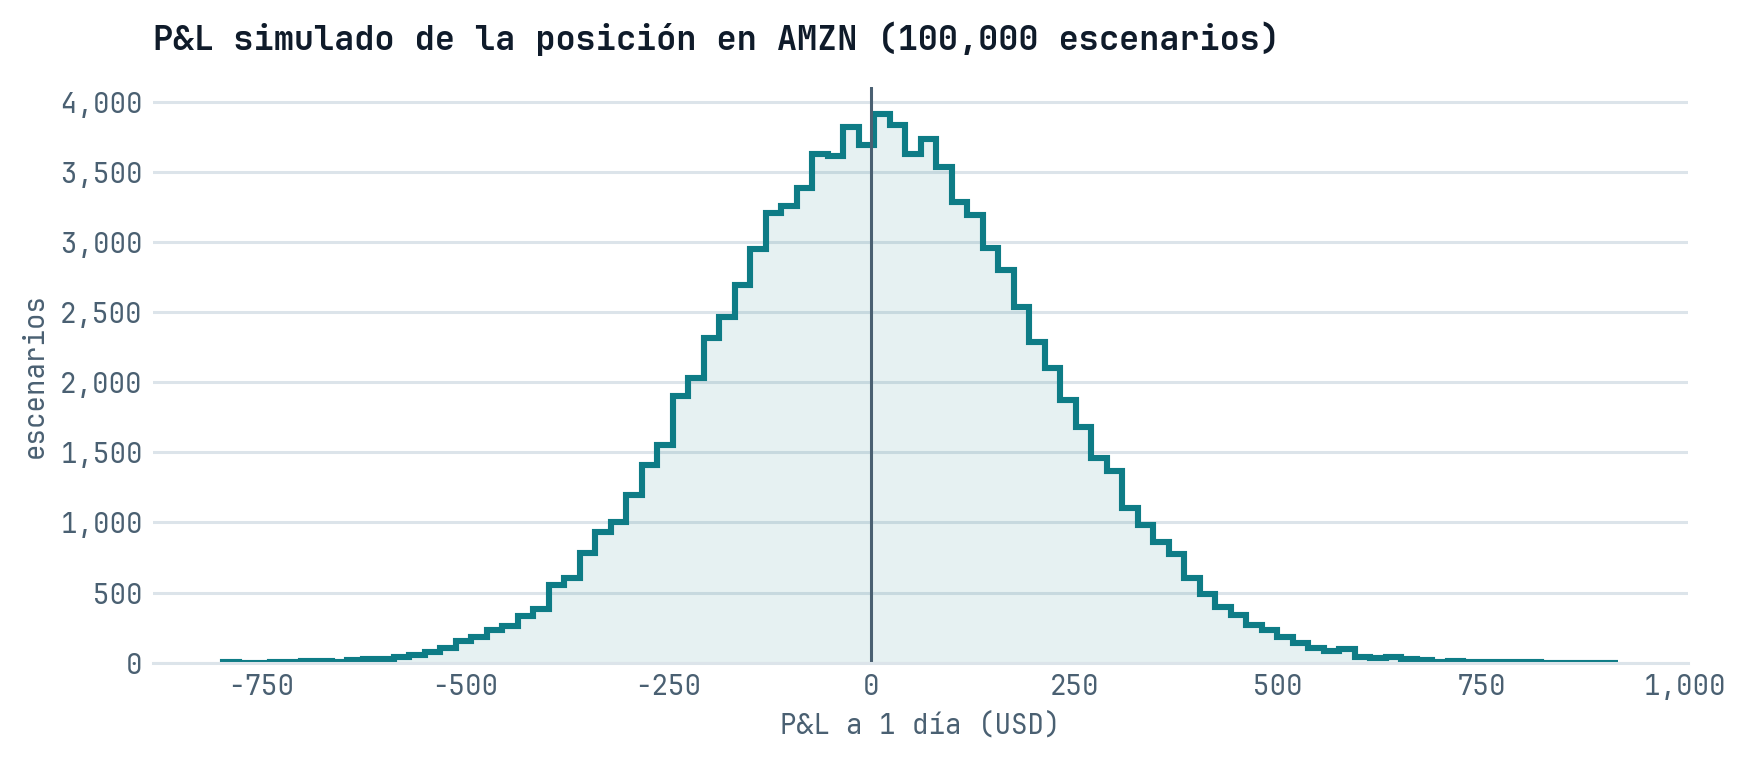

In [14]:
graficas.pnl_simulado(pnl, TICKERS[0])

## Estimación del VaR

Ordenar los P&L simulados y tomar el enésimo peor caso.

In [15]:
# Enésimo peor caso: ordenar el P&L y tomar la posición k = N·(1 - confianza)
pnl_ordenado = np.sort(pnl)
k = int(round(N_SIM * (1 - CONFIANZA)))
var_mc = -pnl_ordenado[k - 1]

# Comparación con el VaR histórico y el paramétrico (normal)
pnl_hist = VALOR_PORTAFOLIO * (np.exp(rendimientos.values @ PESOS) - 1)
var_hist = -np.quantile(pnl_hist, 1 - CONFIANZA)

sigma_p = np.sqrt(PESOS @ cov @ PESOS * HORIZONTE)
z = stats.norm.ppf(1 - CONFIANZA)
var_param = -VALOR_PORTAFOLIO * (np.exp(PESOS @ mu * HORIZONTE + z * sigma_p) - 1)

print(
    f"Escenario k = {k:,} de {N_SIM:,}: con {CONFIANZA:.0%} de confianza, la pérdida a "
    f"{HORIZONTE} día(s) no supera USD {var_mc:,.2f}"
)
pd.DataFrame(
    {"VaR (USD)": [var_mc, var_hist, var_param]},
    index=["Monte Carlo", "Histórico", "Paramétrico normal"],
).assign(
    **{"% del portafolio": lambda d: d["VaR (USD)"] / VALOR_PORTAFOLIO * 100}
).round(
    2
)

Escenario k = 1,000 de 100,000: con 99% de confianza, la pérdida a 1 día(s) no supera USD 450.27


,VaR (USD),% del portafolio
Monte Carlo,450.27,4.50
Histórico,458.44,4.58
Paramétrico normal,446.24,4.46


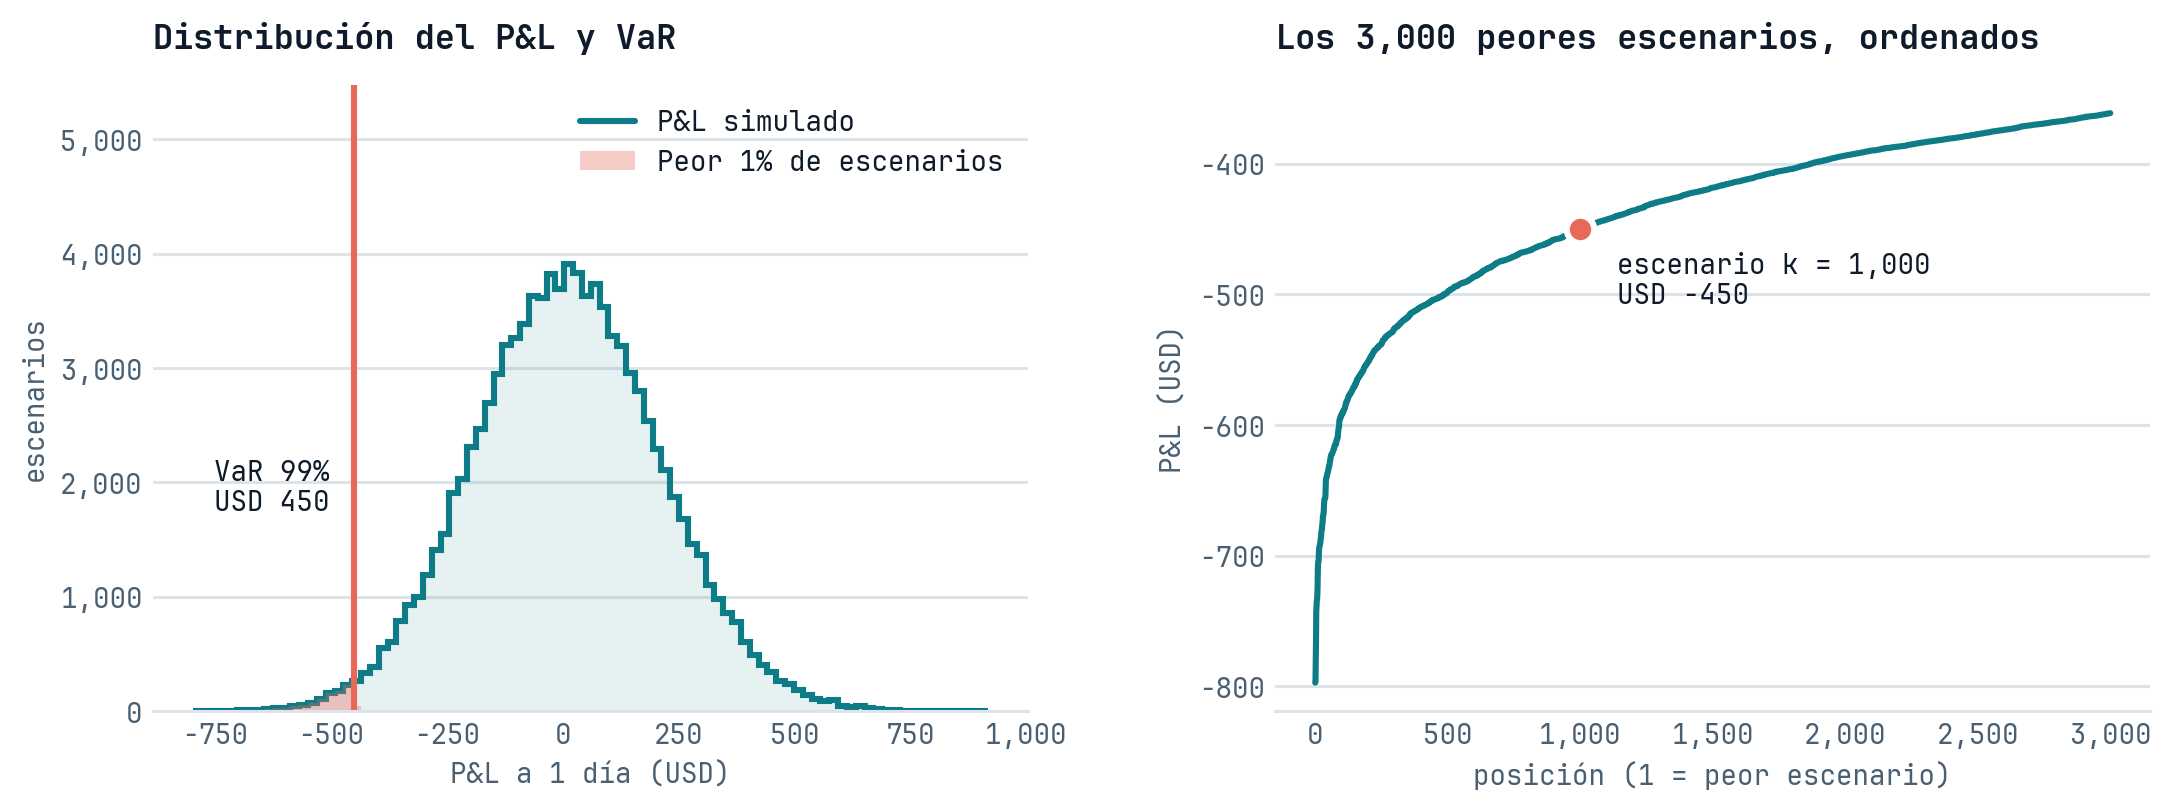

In [16]:
graficas.var_montecarlo(pnl, var_mc, k, CONFIANZA)